# Chapitre 1 - Cours 1 : modèles de langage et tokens

Ce premier notebook accompagne la sous-section *From Language Models to Large Language
Models* du chapitre 1 (section *The Rise of AI Engineering*), et plus précisément son
premier volet, *Language models*. Le livre y pose le vocabulaire de base : qu'est-ce
qu'un modèle de langage, qu'est-ce qu'un **token**, pourquoi les modèles travaillent sur
des morceaux de mots, quelle différence entre un modèle **masqué** et un modèle
**autorégressif**, et pourquoi on peut voir un LLM comme une « completion machine ».

Le livre reste volontairement qualitatif ; on ajoute ici les calculs et les expériences :

1. un modèle de langage encode des statistiques (fréquences, entropie, n-grammes, GPT-2) ;
2. tokens, tokenisation et vocabulaire (cinq tokenizers réels comparés) ;
3. pourquoi des sous-mots ? (un BPE écrit de zéro, compromis vocabulaire / longueur) ;
4. le coût en tokens dépend de la langue (la « taxe » du français et des autres langues) ;
5. modèles masqués et autorégressifs (masques d'attention, BERT-like contre GPT-2) ;
6. le modèle de langage comme machine à compléter (génération pas à pas, tâches
   reformulées en complétion, complétion contre conversation).

In [1]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN,
                          LIGHT, annotate_bars, subtitle, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch01_introduction as c1

c1.setup_style()  # style du socle + repli de police pour les symboles
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 90)

## 1. Un modèle de langage encode des statistiques (section *Language models*)

**Le problème.** Une langue n'est pas une suite aléatoire de symboles : certaines lettres,
certains mots, certaines suites de mots sont bien plus fréquents que d'autres. Un
**modèle de langage** est un objet qui encode ces régularités sous la forme d'une
distribution de probabilité : étant donné un contexte $x_{<t} = (x_1, \dots, x_{t-1})$,
il attribue une probabilité $P(x_t \mid x_{<t})$ à chaque unité possible $x_t$.
Par la règle de la chaîne, cela définit la probabilité de toute une séquence :
$$P(x_1, \dots, x_T) = \prod_{t=1}^{T} P(x_t \mid x_{<t}).$$

**Intuition.** Le livre rappelle que Sherlock Holmes déchiffre les « hommes dansants » en
supposant que le symbole le plus fréquent code la lettre E. C'est le modèle de langage
le plus simple qui soit : des fréquences de lettres **sans aucun contexte**. Vérifions-le
sur un petit corpus français rédigé pour ce dépôt.

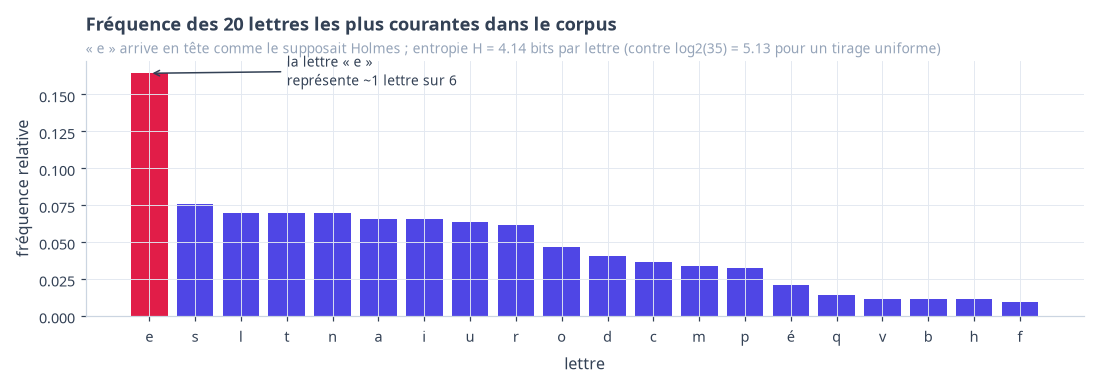

In [2]:
freqs = c1.letter_frequencies(c1.CORPUS_FR)
top = dict(list(freqs.items())[:20])
fig, ax = plt.subplots(figsize=(10, 3.6))
bars = ax.bar(list(top), list(top.values()), color=[ROSE if i == 0 else INDIGO for i in range(len(top))])
ax.set_ylabel("fréquence relative")
ax.set_xlabel("lettre")
H0 = c1.entropy(freqs)
c1.title_sub(ax, "Fréquence des 20 lettres les plus courantes dans le corpus", f"« e » arrive en tête comme le supposait Holmes ; entropie H = {H0:.2f} bits par lettre "
             f"(contre log2({len(freqs)}) = {np.log2(len(freqs)):.2f} pour un tirage uniforme)")
ax.annotate("la lettre « e »\nreprésente ~1 lettre sur 6", xy=(0, top["e"]), xytext=(3, top["e"] * 0.95),
            arrowprops=dict(arrowstyle="->", color=SLATE), fontsize=9)
plt.tight_layout(); plt.show()

**Entropie.** Shannon, dans l'article de 1951 cité par le livre (*Prediction and Entropy
of Printed English*), mesure l'information moyenne d'un symbole par l'**entropie**
$$H(p) = -\sum_i p_i \log_2 p_i \quad \text{(bits)}.$$
Elle vaut $\log_2 V$ pour une distribution uniforme sur $V$ symboles et $0$ si l'issue est
certaine. L'idée centrale de Shannon : **plus on connaît de contexte, plus la lettre
suivante est prévisible**, donc plus l'entropie *conditionnelle* $H(X_t \mid X_{t-k..t-1})$
baisse. Un modèle **n-gramme** de caractères ($k = n-1$ caractères de contexte) permet de
le voir, et de générer des « approximations » de plus en plus crédibles du français.

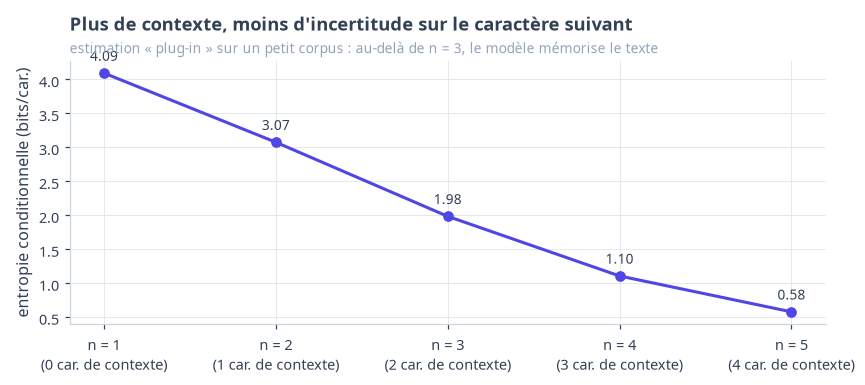

,ordre n,texte généré à partir de « le »
0,1,le csm ei r elemrvdnpd àdetmir pe ouandrqasoosert tei pdtdlenaarrluat vn
1,2,le chriche pale mouent à ete qure puendoratent qu s larduemenceront s à
2,3,le chochef de mentrasse à conne que une ques monst rique tours donst res
3,4,le bien de remierse imment rieurs briquest une mot soleille et du public
4,5,le matine début dune pendant le prend des briquestion traduire une début


In [3]:
text = c1.normalize_text(c1.CORPUS_FR)
orders = [1, 2, 3, 4, 5]
H = [c1.conditional_entropy(text, n) for n in orders]
samples = {n: "le " + c1.CharNGram(order=n, alpha=1e-4).fit(text).generate(70, prompt="le ", seed=3) for n in orders}

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(orders, H, "o-", color=INDIGO)
for n, h in zip(orders, H):
    ax.annotate(f"{h:.2f}", (n, h), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set_xticks(orders, [f"n = {n}\n({n - 1} car. de contexte)" for n in orders])
ax.set_ylabel("entropie conditionnelle (bits/car.)")
c1.title_sub(ax, "Plus de contexte, moins d'incertitude sur le caractère suivant", "estimation « plug-in » sur un petit corpus : au-delà de n = 3, le modèle mémorise le texte")
plt.tight_layout(); plt.show()
pd.DataFrame({"ordre n": orders, "texte généré à partir de « le »": [samples[n] for n in orders]})

Avec $n = 1$ on obtient une soupe de lettres aux bonnes fréquences ; à $n = 3$ des
syllabes et de vrais petits mots apparaissent ; à $n = 5$ des morceaux entiers du
corpus ressortent, car un si petit texte ne contient presque qu'une seule suite possible
pour chaque contexte de 4 caractères. C'est le dilemme fondamental de la modélisation
du langage : **un long contexte est nécessaire, mais le nombre de contextes possibles
explose** ($V^{k}$ pour $k$ symboles de contexte). Les réseaux de neurones (et en
particulier les transformers) résolvent ce problème en **partageant** l'information entre
contextes similaires au lieu de les compter un par un.

Faisons le même test qu'au début de la section *Language models* avec un vrai modèle
neuronal, GPT-2 (124 M paramètres) : après « My favorite color is », le mot « blue »
doit être bien plus probable que « car ».

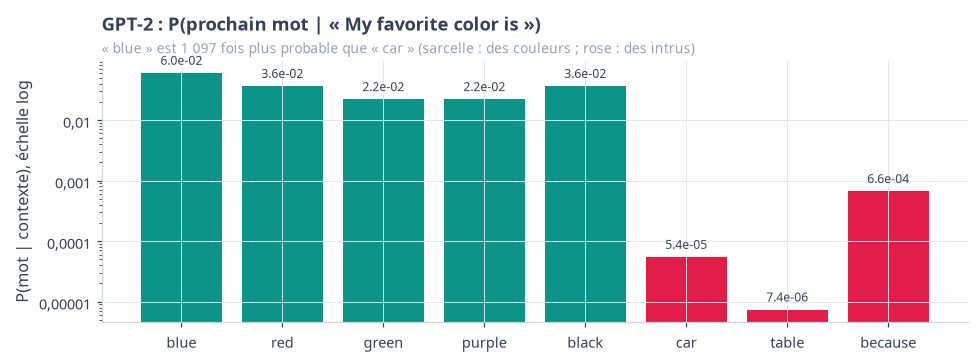

In [4]:
logits = llm.full_logits("My favorite color is", llm.BASE)
probs = llm.softmax(logits)
tok_gpt2, _ = llm.load(llm.BASE)
cands = [" blue", " red", " green", " purple", " black", " car", " table", " because"]
p_c = [probs[tok_gpt2.encode(w)[0]] for w in cands]

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar([w.strip() for w in cands], p_c, color=[TEAL] * 5 + [ROSE] * 3)
ax.set_yscale("log"); c1.plain_log(ax, "y")
ax.set_ylabel("P(mot | contexte), échelle log")
ratio_bc = f"{p_c[0] / p_c[5]:,.0f}".replace(",", " ")
c1.title_sub(ax, "GPT-2 : P(prochain mot | « My favorite color is »)",
             f"« blue » est {ratio_bc} fois plus probable que « car » (sarcelle : des couleurs ; rose : des intrus)")
annotate_bars(ax, "{:.1e}", fontsize=8)
plt.tight_layout(); plt.show()

> **À retenir.** Un modèle de langage est une distribution $P(x_t \mid x_{<t})$ sur l'unité
> suivante. Plus il exploite de contexte, plus son entropie (son incertitude) baisse :
> c'est l'intuition de Shannon, que les LLM poussent à l'extrême avec des contextes de
> milliers de tokens.

## 2. Tokens, tokenisation et vocabulaire (section *Language models*)

**Définitions.** L'unité de base d'un modèle de langage est le **token** : un caractère,
un mot ou un morceau de mot selon le modèle. La **tokenisation** découpe le texte en
tokens, chacun identifié par un entier ; l'ensemble des tokens possibles forme le
**vocabulaire** (de taille $V$). Le livre donne l'exemple de GPT-4, qui coupe « can't »
en deux tokens. Comparons cinq tokenizers réels sur une même phrase :

| tokenizer | modèles | algorithme |
|---|---|---|
| GPT-2 | GPT-2, GPT-3 | BPE sur octets, ~50 k tokens |
| cl100k | GPT-3.5, GPT-4 | BPE sur octets, ~100 k |
| o200k | GPT-4o | BPE sur octets, ~200 k, plus multilingue |
| Qwen2.5 | famille Qwen | BPE sur octets, ~151 k |
| XLM-R | XLM-RoBERTa (BERT multilingue) | SentencePiece unigramme, ~250 k |

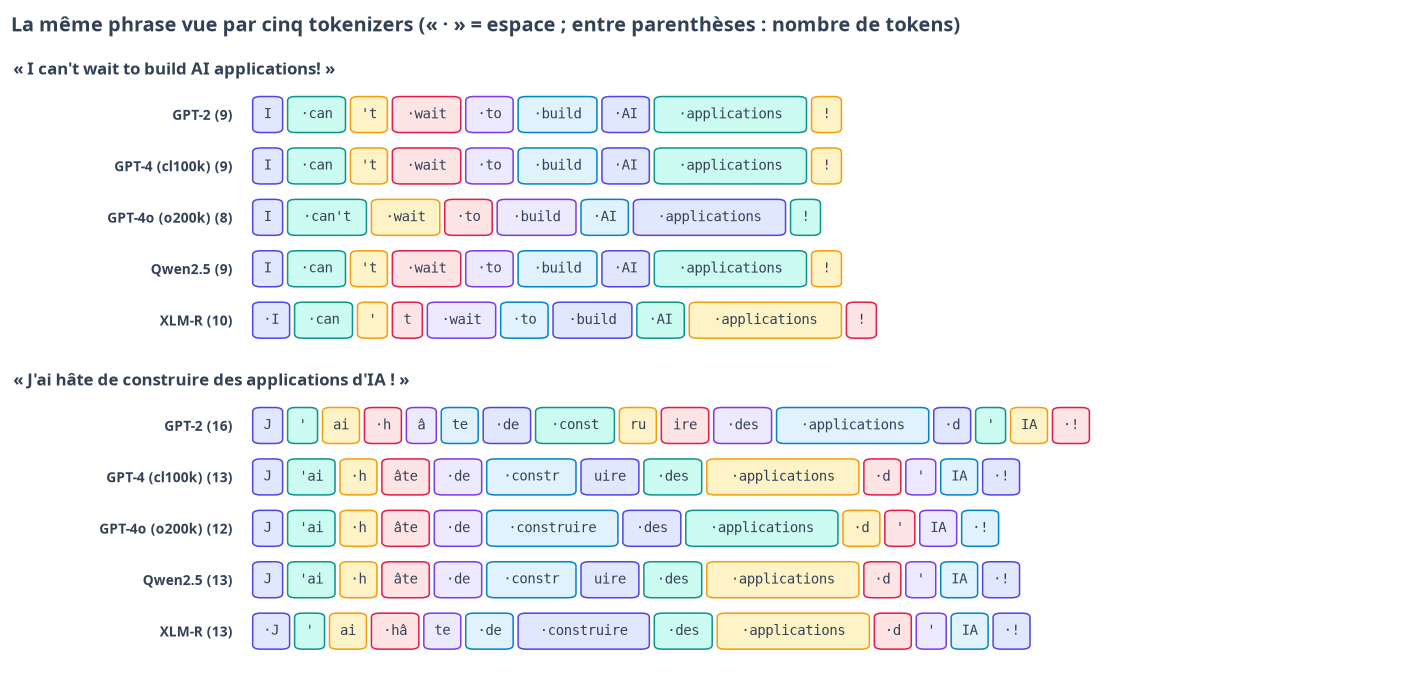

In [5]:
phrases = ["I can't wait to build AI applications!",
           "J'ai hâte de construire des applications d'IA !"]
names = list(c1.TOKENIZERS)
fig, axes = plt.subplots(2, 1, figsize=(13, 6.2))
for ax, ph in zip(axes, phrases):
    for i, n in enumerate(names):
        tk = c1.get_tokenizer(n)
        pcs = tk.pieces(ph)
        c1.draw_tokens(ax, pcs, y=-i, x0=2.4, fontsize=9, char_w=0.105, label=f"{n} ({len(pcs)})")
    ax.set_xlim(0, 14); ax.set_ylim(-len(names) + 0.4, 0.6)
    ax.axis("off")
    ax.set_title(f"« {ph} »", fontsize=11)
finish(fig, "La même phrase vue par cinq tokenizers (« · » = espace ; entre parenthèses : nombre de tokens)")
plt.show()

Quelques observations :

- l'espace fait **partie** du token qui suit (« ·build ») : c'est la convention des BPE
  de type GPT-2 ; SentencePiece (XLM-R) fait de même avec son symbole « ▁ » ;
- en anglais, tous les tokenizers donnent à peu près un token par mot ;
- en français, le tokenizer de GPT-2, appris sur un web essentiellement anglophone,
  **émiette** les mots (« h », « â », « te ») : le même message coûte plus de tokens ;
- les tokenizers plus récents, à vocabulaire plus grand, compressent mieux le français.

**Taille du vocabulaire et ratio mots / tokens.** Le livre indique que pour GPT-4 un token
vaut en moyenne les trois quarts d'un mot (100 tokens ≈ 75 mots). Vérifions-le sur notre
petit corpus anglais.

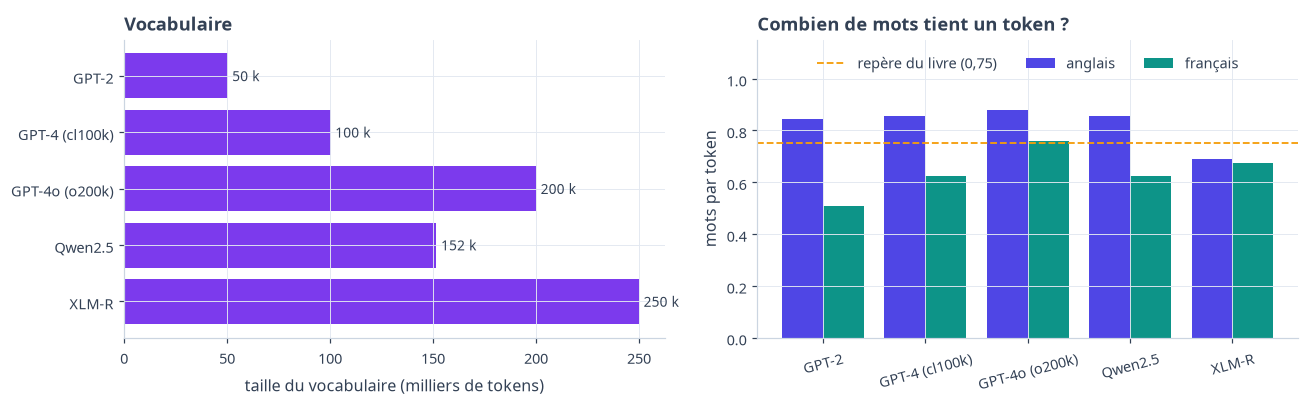

,taille du vocabulaire,mots / token (anglais),mots / token (français)
tokenizer,,,
GPT-2,50257,0.84,0.51
GPT-4 (cl100k),100277,0.86,0.62
GPT-4o (o200k),200019,0.88,0.76
Qwen2.5,151665,0.86,0.62
XLM-R,250002,0.69,0.68


In [6]:
en_text = " ".join(e for e, _ in c1.PARALLEL_EN_FR)
fr_text = " ".join(f for _, f in c1.PARALLEL_EN_FR)
rows = []
for n in names:
    tk = c1.get_tokenizer(n)
    rows.append({"tokenizer": n, "taille du vocabulaire": tk.vocab_size,
                 "mots / token (anglais)": len(c1.words(en_text)) / tk.count(en_text),
                 "mots / token (français)": len(c1.words(fr_text)) / tk.count(fr_text)})
voc = pd.DataFrame(rows).set_index("tokenizer")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].barh(voc.index[::-1], voc["taille du vocabulaire"][::-1] / 1000, color=VIOLET)
axes[0].set_xlabel("taille du vocabulaire (milliers de tokens)")
axes[0].set_title("Vocabulaire")
annotate_bars(axes[0], "{:.0f} k")
x = np.arange(len(voc))
axes[1].bar(x - 0.2, voc["mots / token (anglais)"], 0.4, color=INDIGO, label="anglais")
axes[1].bar(x + 0.2, voc["mots / token (français)"], 0.4, color=TEAL, label="français")
axes[1].axhline(0.75, color=AMBER, ls="--", lw=1.2, label="repère du livre (0,75)")
axes[1].set_ylim(0, 1.15)
axes[1].set_xticks(x, voc.index, rotation=15)
axes[1].set_ylabel("mots par token")
axes[1].set_title("Combien de mots tient un token ?")
axes[1].legend(loc="upper center", ncol=3)
finish(fig); plt.show()
voc.round(2)

Sur nos phrases courtes (beaucoup de ponctuation, d'apostrophes), on obtient un peu moins
de 0,75 mot par token en anglais ; l'ordre de grandeur du livre est le bon. En français,
un token « vaut » nettement moins d'un mot pour GPT-2, et l'écart se resserre avec les
vocabulaires récents.

> **À retenir.** Le token est l'unité de calcul **et** de facturation d'un LLM. La même
> phrase ne coûte pas le même nombre de tokens selon le tokenizer : il faut toujours
> compter avec le tokenizer du modèle réellement utilisé.

## 3. Pourquoi des sous-mots ? (encadré sur les tokens, section *Language models*)

Le livre donne trois raisons de préférer les tokens aux caractères ou aux mots : les
sous-mots portent du sens (« cook » + « ing »), un vocabulaire plus petit que celui des
mots rend le modèle plus efficace, et les mots inconnus restent représentables
(« chatgpting »). Rendons ces trois arguments **quantitatifs**.

**L'algorithme BPE** (*Byte Pair Encoding*, Sennrich et al. 2016) construit le
vocabulaire de façon gloutonne :

1. partir des caractères (ou des 256 octets) comme symboles de base ;
2. compter toutes les paires de symboles adjacents dans le corpus ;
3. fusionner la paire la plus fréquente en un nouveau symbole, l'ajouter au vocabulaire ;
4. recommencer jusqu'à atteindre la taille de vocabulaire voulue.

On l'a écrit en 30 lignes dans `aie/ch01_introduction.py` (`train_bpe`, `bpe_tokenize`).
Le symbole « _ » marque la fin d'un mot.

In [7]:
corpus_words = c1.words(c1.CORPUS_FR.lower())
merges = c1.train_bpe(corpus_words, 300)
pd.DataFrame({"étape": range(1, 13), "paire fusionnée": [f"{a} + {b}" for a, b in merges[:12]],
              "nouveau symbole": [a + b for a, b in merges[:12]]}).set_index("étape").T

étape,1,2,3,4,5,6,7,8,9,10,11,12
paire fusionnée,e + _,s + _,t + _,e + n,l + e_,e + s_,q + u,o + n,d + e_,a + n,en + t_,i + l
nouveau symbole,e_,s_,t_,en,le_,es_,qu,on,de_,an,ent_,il


Les premières fusions capturent les suites les plus fréquentes du français : finales de
mots (« e_ », « s_ »), articles, terminaisons. Appliquons ce BPE (appris sur notre seul
petit corpus) à des mots, dont certains **n'y figurent pas** :

In [8]:
test_words = ["construire", "démonstration", "reconstruire", "chatgptiser", "anticonstitutionnellement"]
rows = []
for w in test_words:
    rows.append({"mot": w, "dans le corpus ?": "oui" if w in corpus_words else "non",
                 "BPE maison (300 fusions)": " | ".join(c1.bpe_tokenize(w, merges)),
                 "GPT-4o (o200k)": " | ".join(c1.get_tokenizer("GPT-4o (o200k)").pieces(" " + w)).strip()})
pd.DataFrame(rows)

,mot,dans le corpus ?,BPE maison (300 fusions),GPT-4o (o200k)
0,construire,oui,construire_,construire
1,démonstration,oui,démonstration_,démon | str | ation
2,reconstruire,non,re | construire_,reconstru | ire
3,chatgptiser,non,ch | at | g | p | ti | s | er_,chat | g | pt | iser
4,anticonstitutionnellement,non,an | ti | const | i | t | u | ti | on | n | el | l | ement_,anticon | stitution | nel | lement


« reconstruire » n'apparaît pas dans le corpus mais se décompose en morceaux connus,
dont une partie de « construire » : le modèle pourra exploiter ce qu'il sait du mot
racine. Aucun mot n'est jamais « hors vocabulaire » puisqu'on peut toujours redescendre
aux caractères (ou aux octets, pour les BPE au niveau des octets).

**Le compromis vocabulaire / longueur de séquence.** Un vocabulaire de caractères est
minuscule mais produit des séquences très longues (coûteuses : le coût de l'attention
croît comme le carré de la longueur, cf. chapitre 2). Un vocabulaire de mots donne des
séquences courtes mais énormes en taille, et ne sait pas traiter un mot nouveau. BPE
parcourt continûment le chemin entre les deux. Mesurons-le, ainsi que le taux de mots
inconnus d'un vocabulaire de mots appris sur la première moitié du corpus.

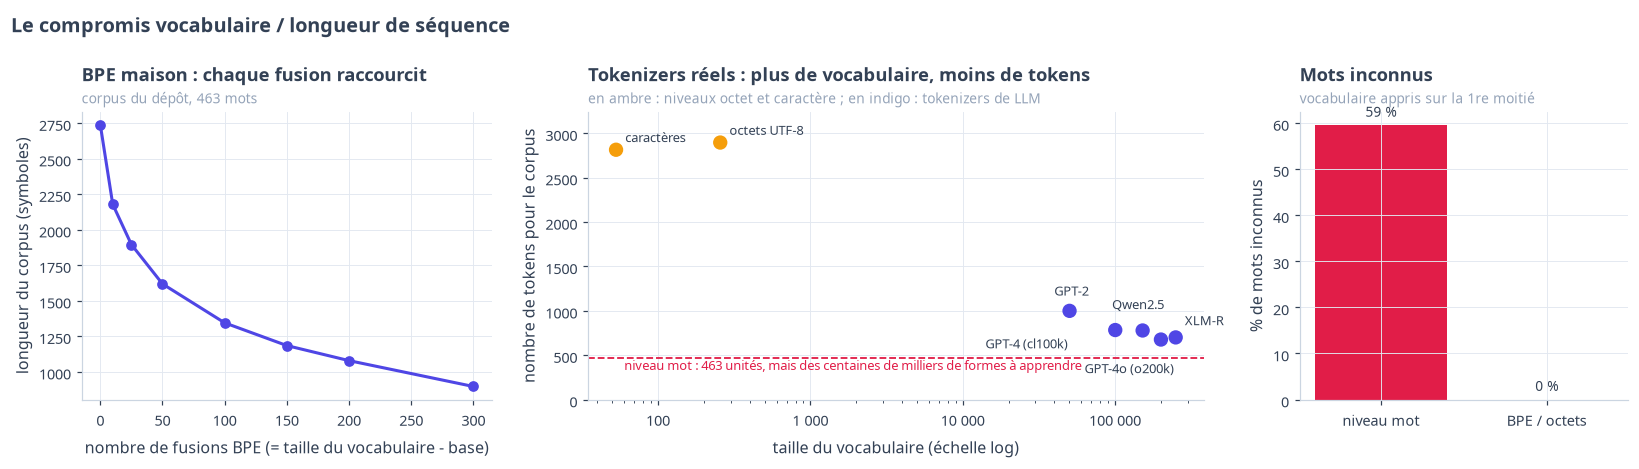

In [9]:
merge_grid = [0, 10, 25, 50, 100, 150, 200, 300]
all_merges = c1.train_bpe(corpus_words, max(merge_grid))
bpe_len = [sum(len(c1.bpe_tokenize(w, all_merges[:m])) for w in corpus_words) for m in merge_grid]

# tokenizers réels sur le même texte, du niveau octet au niveau mot
real = [("octets UTF-8", 256, len(c1.CORPUS_FR.encode("utf-8"))),
        ("caractères", len(set(c1.CORPUS_FR)), len(c1.CORPUS_FR))]
real += [(n, c1.get_tokenizer(n).vocab_size, c1.get_tokenizer(n).count(c1.CORPUS_FR)) for n in names]
n_words = len(c1.words(c1.CORPUS_FR))

half = len(corpus_words) // 2
train_vocab = set(corpus_words[:half])
oov = np.mean([w not in train_vocab for w in corpus_words[half:]])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1, 1.5, 0.8]})
ax = axes[0]
ax.plot(merge_grid, bpe_len, "o-", color=INDIGO)
ax.set_xlabel("nombre de fusions BPE (= taille du vocabulaire - base)")
ax.set_ylabel("longueur du corpus (symboles)")
c1.title_sub(ax, "BPE maison : chaque fusion raccourcit", f"corpus du dépôt, {len(corpus_words)} mots")
ax = axes[1]
labels, V, L = zip(*real)
cols = [AMBER, AMBER] + [INDIGO] * len(names)
ax.scatter(V, L, s=70, color=cols, zorder=5)
offsets = {"GPT-2": (-10, 10), "GPT-4 (cl100k)": (-85, -12), "Qwen2.5": (-20, 14),
           "GPT-4o (o200k)": (-50, -22), "XLM-R": (6, 8)}
for lb, v, l in zip(labels, V, L):
    ax.annotate(lb, (v, l), textcoords="offset points", xytext=offsets.get(lb, (6, 5)), fontsize=8.5)
ax.axhline(n_words, color=ROSE, ls="--", lw=1.2)
ax.text(60, n_words * 0.72, f"niveau mot : {n_words} unités, mais des centaines de milliers de formes à apprendre",
        color=ROSE, fontsize=8.5)
ax.set_xscale("log"); c1.plain_log(ax, "x"); ax.set_ylim(0, max(L) * 1.12)
ax.set_xlabel("taille du vocabulaire (échelle log)")
ax.set_ylabel("nombre de tokens pour le corpus")
c1.title_sub(ax, "Tokenizers réels : plus de vocabulaire, moins de tokens",
             "en ambre : niveaux octet et caractère ; en indigo : tokenizers de LLM")
axes[2].bar(["niveau mot", "BPE / octets"], [oov * 100, 0], color=[ROSE, TEAL])
axes[2].set_ylabel("% de mots inconnus")
c1.title_sub(axes[2], "Mots inconnus", "vocabulaire appris sur la 1re moitié")
annotate_bars(axes[2], "{:.0f} %")
finish(fig, "Le compromis vocabulaire / longueur de séquence"); plt.show()

Le niveau octet est imbattable en taille de vocabulaire (256) mais produit des séquences
environ quatre fois plus longues qu'un tokenizer de LLM. Le niveau mot donnerait les
séquences les plus courtes, au prix d'un vocabulaire gigantesque. Les concepteurs
choisissent un point de compromis (32 k pour Mixtral, ~100 k pour GPT-4,
~150 k à 250 k pour les modèles très multilingues). Avec un vocabulaire de mots, une
grosse fraction des mots de la seconde moitié du corpus serait inconnue (graphique de
droite) : c'est le défaut rédhibitoire que la tokenisation en sous-mots élimine.

> **À retenir.** Les sous-mots sont un compromis : assez gros pour porter du sens et
> raccourcir les séquences, assez petits pour que le vocabulaire reste raisonnable et que
> tout mot (même inventé) reste représentable.